# ML vs DL for Early At-Risk Student Prediction (OULAD)

Starter pipeline for a comparative evaluation of classical machine learning
(Logistic Regression, Random Forest, XGBoost) and deep learning (LSTM, GRU)
for early identification of at-risk students, evaluated at multiple
prediction horizons on the **Open University Learning Analytics Dataset (OULAD)**.

**Runtime:** works on a free Colab GPU (`Runtime > Change runtime type > T4 GPU`).
Full run over 5 horizons takes roughly 20-40 minutes.

**Outputs:**
1. A results table (AUC, F1, at-risk recall, training time) per model per horizon
2. The "money figure": AUC vs. prediction week, one line per model
3. A SHAP summary plot for XGBoost (interpretability dimension)


In [ ]:
# --- Setup ---------------------------------------------------------------
!pip -q install shap

import os, time, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, f1_score, recall_score
import xgboost as xgb

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
HORIZONS = [4, 8, 12, 16, 20]          # prediction points, in weeks from course start
KEY = ["code_module", "code_presentation", "id_student"]
print("Device:", DEVICE)

Device: cuda


## 1. Download OULAD

Downloads directly from the Open University. If the direct download fails,
search Kaggle for "OULAD", add it to the notebook via **Add data**, and point
`D` at that folder instead — the CSV file names are identical.


In [ ]:
# ============================================================
# STEP 1 - Download OULAD from Kaggle
# ============================================================

import os
import kagglehub
import pandas as pd
import numpy as np

# Keys used throughout the notebook
KEY = ["code_module", "code_presentation", "id_student"]

# Download dataset
DATA_DIR = kagglehub.dataset_download(
    "anlgrbz/student-demographics-online-education-dataoulad"
)

print("Dataset location:")
print(DATA_DIR)

print("\nFiles in dataset:")
print(sorted(os.listdir(DATA_DIR)))

Using Colab cache for faster access to the 'student-demographics-online-education-dataoulad' dataset.
Dataset location:
/kaggle/input/student-demographics-online-education-dataoulad

Files in dataset:
['assessments.csv', 'courses.csv', 'studentAssessment.csv', 'studentInfo.csv', 'studentRegistration.csv', 'studentVle.csv', 'vle.csv']


## 2. Labels and base cohort

At-risk = final result `Fail` or `Withdrawn`. Students who unregistered before
the course started are excluded (they never participated, so predicting them
is meaningless). Later, at each horizon we additionally drop students who had
already withdrawn by that week — an early-warning system only scores
*currently enrolled* students, and keeping withdrawn students would leak the label.


In [ ]:
# ============================================================
# STEP 2 - Create labels and base cohort
# ============================================================

info = pd.read_csv(
    os.path.join(DATA_DIR, "studentInfo.csv")
)

reg = pd.read_csv(
    os.path.join(DATA_DIR, "studentRegistration.csv")
)

# Merge registration information
df = info.merge(
    reg,
    on=KEY,
    how="left"
)

# Remove students who withdrew before course start
df = df[
    ~(
        df["date_unregistration"] < 0
    )
].copy()

# Binary target
# 1 = Fail or Withdrawn
# 0 = Pass or Distinction
df["at_risk"] = (
    df["final_result"]
    .isin(["Fail", "Withdrawn"])
    .astype(int)
)

print("Class balance (1 = at-risk):")
print(
    df["at_risk"]
    .value_counts(normalize=True)
    .round(3)
)

print("\nCounts:")
print(
    df["at_risk"]
    .value_counts()
)

print("\nFinal result distribution:")
print(
    df["final_result"]
    .value_counts()
)

Class balance (1 = at-risk):
at_risk
0    0.514
1    0.486
Name: proportion, dtype: float64

Counts:
at_risk
0    15385
1    14530
Name: count, dtype: int64

Final result distribution:
final_result
Pass           12361
Withdrawn       7480
Fail            7050
Distinction     3024
Name: count, dtype: int64


## 3. Clickstream preparation

We attach the activity type to every click record and bucket days into weeks.
To keep the feature space manageable we keep the 10 most frequent activity
types and pool the rest into `other`.


In [ ]:
# ============================================================
# STEP 3 - Clickstream Preparation
# ============================================================

# Load clickstream tables
svle = pd.read_csv(
    os.path.join(DATA_DIR, "studentVle.csv")
)

vle = pd.read_csv(
    os.path.join(DATA_DIR, "vle.csv")
)

# Attach activity type to each click record
svle = svle.merge(
    vle[["id_site", "activity_type"]]
        .drop_duplicates("id_site"),
    on="id_site",
    how="left"
)

# Keep the 10 most frequent activity types
top_types = (
    svle["activity_type"]
    .value_counts()
    .head(10)
    .index
    .tolist()
)

# Pool remaining activities into "other"
svle["atype"] = np.where(
    svle["activity_type"].isin(top_types),
    svle["activity_type"],
    "other"
)

# Final activity channels
TYPES = top_types + ["other"]

# Convert days to weeks
# Pre-course clicks become week 0
svle["week"] = (
    svle["date"] // 7
).clip(lower=0)

print("Activity channels:")
print(TYPES)

print("\nNumber of channels:", len(TYPES))

print("\nPreview:")
print(
    svle[
        [
            "code_module",
            "code_presentation",
            "id_student",
            "date",
            "week",
            "sum_click",
            "atype"
        ]
    ].head()
)

Activity channels:
['forumng', 'oucontent', 'subpage', 'homepage', 'quiz', 'resource', 'url', 'ouwiki', 'oucollaborate', 'externalquiz', 'other']

Number of channels: 11

Preview:
  code_module code_presentation  id_student  date  week  sum_click      atype
0         AAA             2013J       28400   -10     0          4    forumng
1         AAA             2013J       28400   -10     0          1    forumng
2         AAA             2013J       28400   -10     0          1    forumng
3         AAA             2013J       28400   -10     0         11   homepage
4         AAA             2013J       28400   -10     0          1  oucontent


In [ ]:
# ============================================================
# Assessment tables
# ============================================================

sassess = pd.read_csv(
    os.path.join(DATA_DIR, "studentAssessment.csv")
)

assess = pd.read_csv(
    os.path.join(DATA_DIR, "assessments.csv")
)

print("studentAssessment shape:", sassess.shape)
print("assessments shape:", assess.shape)

studentAssessment shape: (173912, 5)
assessments shape: (206, 6)


In [ ]:
print(sassess.columns.tolist())
print(assess.columns.tolist())

['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score']
['code_module', 'code_presentation', 'id_assessment', 'assessment_type', 'date', 'weight']


## 4. Feature engineering (classical models)

For a horizon of `H` weeks, classical models see hand-crafted aggregates of
everything observed strictly before day `H*7`:

* engagement: total clicks, clicks per activity type, active days, days since
  last activity, linear weekly click trend (slope)
* assessments: number submitted, mean score
* demographics: one-hot encoded (run your ablation with/without these)


In [ ]:
DEMO_CAT = ["gender", "highest_education", "imd_band", "age_band", "disability"]
DEMO_NUM = ["num_of_prev_attempts", "studied_credits"]

def build_tabular(H, cohort):
    hdays = H * 7
    clicks = svle[svle.date < hdays]

    g = clicks.groupby(KEY)
    feats = g.agg(total_clicks=("sum_click", "sum"),
                  active_days=("date", "nunique"),
                  last_day=("date", "max")).reset_index()
    feats["days_since_last"] = hdays - feats.last_day
    feats = feats.drop(columns="last_day")

    pt = clicks.pivot_table(index=KEY, columns="atype", values="sum_click",
                            aggfunc="sum", fill_value=0)
    pt = pt.add_prefix("clk_").reset_index()
    feats = feats.merge(pt, on=KEY, how="left")

    # vectorised least-squares slope of weekly clicks
    wk = clicks.groupby(KEY + ["week"]).sum_click.sum().reset_index()
    wk["w2"] = wk.week ** 2
    wk["wc"] = wk.week * wk.sum_click
    a = wk.groupby(KEY).agg(n=("week", "size"), sw=("week", "sum"),
                            sc=("sum_click", "sum"), sww=("w2", "sum"),
                            swc=("wc", "sum")).reset_index()
    den = a.n * a.sww - a.sw ** 2
    a["click_slope"] = np.where(den > 0, (a.n * a.swc - a.sw * a.sc) / den, 0.0)
    feats = feats.merge(a[KEY + ["click_slope"]], on=KEY, how="left")

    sa = sassess.merge(assess[["id_assessment"] + KEY[:2]], on="id_assessment")
    sa = sa[sa.date_submitted < hdays]
    ag = sa.groupby(KEY).agg(n_submitted=("score", "count"),
                             mean_score=("score", "mean")).reset_index()
    feats = feats.merge(ag, on=KEY, how="left")

    base = cohort.merge(feats, on=KEY, how="left")
    eng_cols = [c for c in base.columns if c.startswith("clk_")] +                ["total_clicks", "active_days", "days_since_last",
                "click_slope", "n_submitted", "mean_score"]
    base["days_since_last"] = base["days_since_last"].fillna(hdays)
    base[eng_cols] = base[eng_cols].fillna(0)

    X = pd.concat([base[eng_cols + DEMO_NUM],
                   pd.get_dummies(base[DEMO_CAT].fillna("unknown"))], axis=1)
    return X.astype(np.float32), base.at_risk.values

# Patch: Information Parity + Cohort Holdout

Drop-in replacements for your existing notebook. Run your current cells through
**section 4 (`build_tabular`)** unchanged, then use the cells below **instead of**
your old sections 5-7.

What changes:

1. **`build_sequences_v2`** — the sequence tensor gains 2 assessment channels
   (weekly mean score, weekly submission count), so shape becomes `(N, H, 13)`.
2. **`RNNClassifierV2`** — the recurrent output is concatenated with a static
   demographic vector before the classification head. Deep models now see
   exactly the same information as the classical models: clickstream +
   assessments + demographics. The comparison is information-fair.
3. **Cohort holdout** — train on the 2013 presentations (`2013B`, `2013J`),
   test on 2014 (`2014B`, `2014J`). This replaces the random 80/20 split and
   tests generalisation to a new academic year.


## 5. Sequence representation v2 (clicks + assessment channels)

In [ ]:
def build_sequences_v2(H, cohort):
    """(N, H, 13) tensor: 11 log-scaled click channels + weekly mean assessment
    score (0-1) + weekly submission count."""
    n_click = len(TYPES)
    X = np.zeros((len(cohort), H, n_click + 2), dtype=np.float32)

    ridx = cohort[KEY].copy()
    ridx["ridx"] = np.arange(len(ridx))

    # --- click channels (unchanged) ---------------------------------------
    clicks = svle[(svle.date >= 0) & (svle.date < H * 7)]
    wk = clicks.groupby(KEY + ["week", "atype"]).sum_click.sum().reset_index()
    wk = wk.merge(ridx, on=KEY, how="inner")
    t_idx = {t: i for i, t in enumerate(TYPES)}
    X[wk.ridx.values, wk.week.values.astype(int), wk.atype.map(t_idx).values] = \
        np.log1p(wk.sum_click.values)

    # --- assessment channels ----------------------------------------------
    sa = sassess.merge(assess[["id_assessment"] + KEY[:2]], on="id_assessment")
    sa = sa[(sa.date_submitted >= 0) & (sa.date_submitted < H * 7)].copy()
    sa["week"] = sa.date_submitted // 7
    ag = sa.groupby(KEY + ["week"]).agg(mean_score=("score", "mean"),
                                        n_sub=("score", "count")).reset_index()
    ag = ag.merge(ridx, on=KEY, how="inner")
    w = ag.week.values.astype(int)
    X[ag.ridx.values, w, n_click]     = ag.mean_score.fillna(0).values / 100.0
    X[ag.ridx.values, w, n_click + 1] = ag.n_sub.values
    return X


def build_static(cohort):
    """Static demographic matrix, aligned to cohort rows. Dummy columns are
    defined once on the full df so they are identical at every horizon."""
    global _STATIC
    if "_STATIC" not in globals():
        dummies = pd.get_dummies(df[DEMO_CAT].fillna("unknown"))
        _STATIC = pd.concat([df[KEY].reset_index(drop=True),
                             dummies.reset_index(drop=True),
                             df[DEMO_NUM].reset_index(drop=True)], axis=1)
    S = cohort[KEY].merge(_STATIC, on=KEY, how="left")
    return S.drop(columns=KEY).astype(np.float32).values

## 6. Model v2: recurrent encoder + static-feature fusion

In [ ]:
class RNNClassifierV2(nn.Module):
    def __init__(self, n_seq_feat, n_static, hidden=64, cell="lstm"):
        super().__init__()
        rnn = nn.LSTM if cell == "lstm" else nn.GRU
        self.rnn = rnn(n_seq_feat, hidden, batch_first=True)
        self.head = nn.Sequential(
            nn.Linear(hidden + n_static, 64), nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1))

    def forward(self, x_seq, x_static):
        out, _ = self.rnn(x_seq)
        z = torch.cat([out[:, -1], x_static], dim=1)
        return self.head(z).squeeze(-1)


def train_rnn_v2(Xtr, Str, ytr, Xte, Ste, cell="lstm",
                 epochs=30, patience=5, batch=256):
    itr, ival = train_test_split(np.arange(len(ytr)), test_size=0.1,
                                 stratify=ytr, random_state=SEED)

    def loader(idx, shuffle):
        ds = TensorDataset(torch.tensor(Xtr[idx]), torch.tensor(Str[idx]),
                           torch.tensor(ytr[idx], dtype=torch.float32))
        return DataLoader(ds, batch_size=batch, shuffle=shuffle)

    model = RNNClassifierV2(Xtr.shape[2], Str.shape[1], cell=cell).to(DEVICE)
    pos_w = torch.tensor((ytr == 0).sum() / max((ytr == 1).sum(), 1),
                         dtype=torch.float32, device=DEVICE)
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)

    best_auc, best_state, wait = 0.0, None, 0
    for ep in range(epochs):
        model.train()
        for xb, sb, yb in loader(itr, True):
            opt.zero_grad()
            loss = crit(model(xb.to(DEVICE), sb.to(DEVICE)), yb.to(DEVICE))
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            pv = torch.sigmoid(model(torch.tensor(Xtr[ival]).to(DEVICE),
                                     torch.tensor(Str[ival]).to(DEVICE))).cpu().numpy()
        auc = roc_auc_score(ytr[ival], pv)
        if auc > best_auc:
            best_auc, wait = auc, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        preds = torch.sigmoid(model(torch.tensor(Xte).to(DEVICE),
                                    torch.tensor(Ste).to(DEVICE))).cpu().numpy()
    return preds

## 7. Experiment loop v2: cohort holdout (train 2013 → test 2014)

All five models see the same students, the same split, and the same
information. The static demographic vector fed to the RNNs is standardised
with statistics fitted on the **training cohort only** — same discipline as
the classical scaler, no test leakage.

Note the at-risk recall is now computed on a *future academic year*, which is
the deployment-realistic number for your paper.


In [ ]:
import re

TRAIN_PRES = ["2013B", "2013J"]
TEST_PRES  = ["2014B", "2014J"]

results_v2 = []

for H in HORIZONS:
    print(f"\n=== Horizon: week {H} (train 2013 -> test 2014) ===")
    hdays = H * 7
    cohort = df[df.date_unregistration.isna() | (df.date_unregistration >= hdays)]
    cohort = cohort.reset_index(drop=True)

    tr = np.where(cohort.code_presentation.isin(TRAIN_PRES))[0]
    te = np.where(cohort.code_presentation.isin(TEST_PRES))[0]

    Xtab, y = build_tabular(H, cohort)
    Xtab.columns = [re.sub(r"\[|\]|<", "_", str(c)) for c in Xtab.columns]

    Xseq = build_sequences_v2(H, cohort)
    S = build_static(cohort)
    s_scaler = StandardScaler().fit(S[tr])          # fit on train only
    S = s_scaler.transform(S).astype(np.float32)

    print(f"train={len(tr):,}  test={len(te):,}  "
          f"at-risk rate train={y[tr].mean():.3f} test={y[te].mean():.3f}")

    def record(name, preds, secs):
        yhat = (preds >= 0.5).astype(int)
        results_v2.append(dict(model=name, week=H,
                               auc=roc_auc_score(y[te], preds),
                               f1=f1_score(y[te], yhat),
                               recall_at_risk=recall_score(y[te], yhat),
                               train_secs=secs))
        print(f"  {name:12s} AUC={results_v2[-1]['auc']:.3f}  "
              f"recall={results_v2[-1]['recall_at_risk']:.3f}  ({secs:.0f}s)")

    # ---- classical -------------------------------------------------------
    scaler = StandardScaler().fit(Xtab.iloc[tr])
    t0 = time.time()
    lr = LogisticRegression(max_iter=2000, class_weight="balanced")
    lr.fit(scaler.transform(Xtab.iloc[tr]), y[tr])
    record("LogReg", lr.predict_proba(scaler.transform(Xtab.iloc[te]))[:, 1],
           time.time() - t0)

    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                random_state=SEED, n_jobs=-1)
    rf.fit(Xtab.iloc[tr], y[tr])
    record("RandomForest", rf.predict_proba(Xtab.iloc[te])[:, 1], time.time() - t0)

    t0 = time.time()
    xgb_clf = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                                tree_method="hist", eval_metric="auc",
                                scale_pos_weight=(y[tr] == 0).sum() / (y[tr] == 1).sum(),
                                random_state=SEED)
    xgb_clf.fit(Xtab.iloc[tr], y[tr])
    record("XGBoost", xgb_clf.predict_proba(Xtab.iloc[te])[:, 1], time.time() - t0)

    # ---- deep (now information-fair) --------------------------------------
    for cell_type in ["lstm", "gru"]:
        t0 = time.time()
        preds = train_rnn_v2(Xseq[tr], S[tr], y[tr], Xseq[te], S[te], cell=cell_type)
        record(cell_type.upper(), preds, time.time() - t0)

res_v2 = pd.DataFrame(results_v2)
res_v2.round(3)


=== Horizon: week 4 (train 2013 -> test 2014) ===
train=11,818  test=15,735  at-risk rate train=0.444 test=0.440
  LogReg       AUC=0.710  recall=0.593  (0s)
  RandomForest AUC=0.743  recall=0.562  (7s)
  XGBoost      AUC=0.737  recall=0.619  (1s)
  LSTM         AUC=0.738  recall=0.597  (10s)
  GRU          AUC=0.733  recall=0.601  (6s)

=== Horizon: week 8 (train 2013 -> test 2014) ===
train=11,434  test=15,098  at-risk rate train=0.425 test=0.416
  LogReg       AUC=0.766  recall=0.627  (0s)
  RandomForest AUC=0.792  recall=0.580  (6s)
  XGBoost      AUC=0.778  recall=0.632  (1s)
  LSTM         AUC=0.779  recall=0.691  (7s)
  GRU          AUC=0.782  recall=0.642  (6s)

=== Horizon: week 12 (train 2013 -> test 2014) ===
train=11,138  test=14,595  at-risk rate train=0.410 test=0.396
  LogReg       AUC=0.809  recall=0.668  (0s)
  RandomForest AUC=0.817  recall=0.606  (6s)
  XGBoost      AUC=0.805  recall=0.643  (1s)
  LSTM         AUC=0.793  recall=0.688  (5s)
  GRU          AUC=0.804  

,model,week,auc,f1,recall_at_risk,train_secs
0,LogReg,4,0.710,0.607,0.593,0.101
1,RandomForest,4,0.743,0.614,0.562,7.292
2,XGBoost,4,0.737,0.629,0.619,1.292
3,LSTM,4,0.738,0.623,0.597,10.158
4,GRU,4,0.733,0.622,0.601,6.295
5,LogReg,8,0.766,0.641,0.627,0.250
6,RandomForest,8,0.792,0.643,0.580,6.347
7,XGBoost,8,0.778,0.652,0.632,1.110
8,LSTM,8,0.779,0.661,0.691,6.979
9,GRU,8,0.782,0.654,0.642,5.604


## 8. Money figure v2

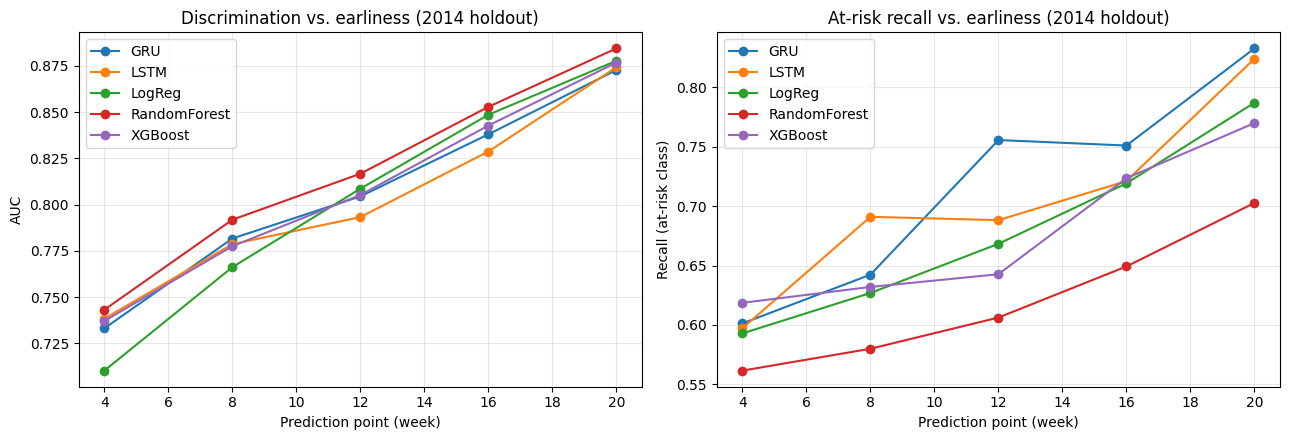

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for m, g in res_v2.groupby("model"):
    axes[0].plot(g.week, g.auc, marker="o", label=m)
    axes[1].plot(g.week, g.recall_at_risk, marker="o", label=m)
axes[0].set(xlabel="Prediction point (week)", ylabel="AUC",
            title="Discrimination vs. earliness (2014 holdout)")
axes[1].set(xlabel="Prediction point (week)", ylabel="Recall (at-risk class)",
            title="At-risk recall vs. earliness (2014 holdout)")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig("auc_vs_horizon_holdout.png", dpi=200, bbox_inches="tight")
plt.show()

## Sanity checks + what to compare

* Test at-risk rates will differ slightly from train — that's the point of the
  holdout; report both rates in your dataset table.
* Compare `res_v2` against your earlier `res`: (a) did the DL-vs-ML gap close
  once the RNNs got assessments + demographics? (b) did everyone's AUC drop a
  little on the year holdout vs. the random split? A small drop is normal and
  worth one sentence in the paper — it quantifies the optimism of random splits.
* Next upgrades, unchanged: 5 seeds per configuration, Friedman + Nemenyi,
  then the equal Optuna budget.


## 9. Interpretability: SHAP for XGBoost (week 8)

Re-trains XGBoost at the week-8 horizon and plots SHAP values — the
interpretability dimension of your comparison. For the deep models, the
analogous analysis is attention weights or integrated gradients (e.g. via
`captum`), which you can compare qualitatively in the paper.


/tmp/ipykernel_3699/1966954042.py:37: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, sample_data, max_display=15)


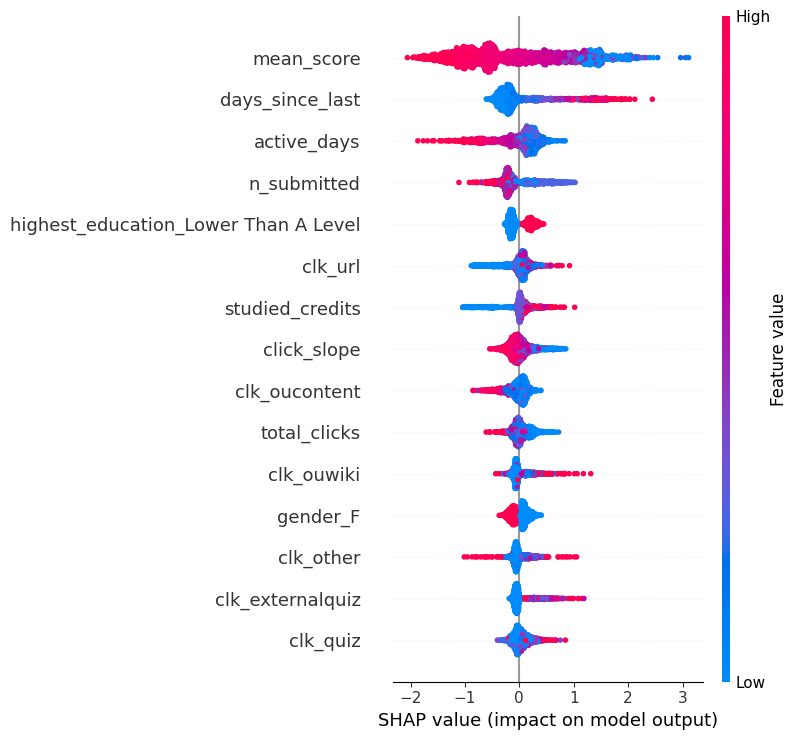

In [ ]:
import re
import shap
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split

H = 8
cohort = df[df.date_unregistration.isna() | (df.date_unregistration >= H * 7)]
cohort = cohort.reset_index(drop=True)

# 1. Generate the tabular data
Xtab, y = build_tabular(H, cohort)

# ---- FIX: Clean column names for XGBoost right after creation ----
regex = re.compile(r"\[|\]|<", re.IGNORECASE)
Xtab.columns = [
    regex.sub("_", col) if any(x in str(col) for x in ["[", "]", "<"]) else col
    for col in Xtab.columns
]
Xtab.columns = Xtab.columns.astype(str)
# ------------------------------------------------------------------

# 2. Split data
tr, te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)

# 3. Train the model
model = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                          tree_method="hist", random_state=SEED)
model.fit(Xtab.iloc[tr], y[tr])

# 4. Run SHAP explanations
explainer = shap.TreeExplainer(model)
sample_data = Xtab.iloc[te].sample(2000, random_state=SEED)
sv = explainer.shap_values(sample_data)

# 5. Generate plot
shap.summary_plot(sv, sample_data, max_display=15)

## 10. Upgrades before submission

1. **Cohort holdout** — train on `code_presentation` values ending in `2013B/2013J`,
   test on `2014B/2014J`. Replaces the random split and tests generalisation to
   a new academic year.
2. **Repeated runs + significance** — 5 seeds per model per horizon, then a
   Friedman test with post-hoc Nemenyi (or pairwise Wilcoxon) across models.
   `scipy.stats` and the `scikit-posthocs` package cover both.
3. **Equal tuning budget** — replace the default hyperparameters with an
   Optuna search of ~30 trials per model, identical budget for classical and
   deep, and report the search spaces in a table.
4. **More deep baselines** — a 1D-CNN and a small transformer encoder slot
   directly into `train_rnn`'s place; both train fine on a T4.
5. **Ablations** — with/without demographics (fairness angle), and
   sequence-only vs. sequence+assessment channels.
6. **Cost table** — you're already logging `train_secs`; add per-student
   inference time and peak GPU memory (`torch.cuda.max_memory_allocated()`).


# Final Experiments Patch: Multi-Seed + Significance Testing

This produces your **paper-ready results**: 5 seeds x 5 models x 5 horizons on
the 2013 -> 2014 cohort holdout, logged to a single CSV (the source of truth
for every number in the manuscript), plus Friedman + Nemenyi significance
tests, the critical-difference diagram, an alert-rate recall metric, and the
final money figure with error bands.

**Prerequisites** — run these from your existing notebooks first, in order:
1. Main notebook: setup/imports, data loading, labels (`df`), clickstream prep
   (`svle`, `TYPES`), and `build_tabular` (section 4).
2. Parity patch: `build_sequences_v2` and `build_static` (section 5).

Everything else (model, training, metrics, stats) is self-contained below.

**Runtime:** roughly 30-45 min on a T4. Total: 125 model fits.


In [ ]:
!pip -q install scikit-posthocs

import re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import scikit_posthocs as sp
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, f1_score, recall_score
import xgboost as xgb

SEEDS = [0, 1, 2, 3, 4]
ALERT_RATE = 0.25            # flag the top 25% highest-risk students
TRAIN_PRES = ["2013B", "2013J"]
TEST_PRES  = ["2014B", "2014J"]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


## 1. Seeded model + metrics

`recall_at_alert_rate` is the threshold-free operational metric: if the
institution can intervene with the top 25% highest-risk students, what
fraction of the truly at-risk does each model catch? Unlike recall at a 0.5
cutoff, this is immune to calibration differences between class-weighted
models, so it's the fair cross-family comparison for the paper.


In [ ]:
class RNNClassifierV2(nn.Module):
    def __init__(self, n_seq_feat, n_static, hidden=64, cell="lstm"):
        super().__init__()
        rnn = nn.LSTM if cell == "lstm" else nn.GRU
        self.rnn = rnn(n_seq_feat, hidden, batch_first=True)
        self.head = nn.Sequential(
            nn.Linear(hidden + n_static, 64), nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1))

    def forward(self, x_seq, x_static):
        out, _ = self.rnn(x_seq)
        z = torch.cat([out[:, -1], x_static], dim=1)
        return self.head(z).squeeze(-1)


def train_rnn_seeded(Xtr, Str, ytr, Xte, Ste, seed, cell="lstm",
                     epochs=30, patience=5, batch=256):
    torch.manual_seed(seed)
    itr, ival = train_test_split(np.arange(len(ytr)), test_size=0.1,
                                 stratify=ytr, random_state=seed)

    def loader(idx, shuffle):
        ds = TensorDataset(torch.tensor(Xtr[idx]), torch.tensor(Str[idx]),
                           torch.tensor(ytr[idx], dtype=torch.float32))
        return DataLoader(ds, batch_size=batch, shuffle=shuffle)

    model = RNNClassifierV2(Xtr.shape[2], Str.shape[1], cell=cell).to(DEVICE)
    pos_w = torch.tensor((ytr == 0).sum() / max((ytr == 1).sum(), 1),
                         dtype=torch.float32, device=DEVICE)
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)

    best_auc, best_state, wait = 0.0, None, 0
    for ep in range(epochs):
        model.train()
        for xb, sb, yb in loader(itr, True):
            opt.zero_grad()
            loss = crit(model(xb.to(DEVICE), sb.to(DEVICE)), yb.to(DEVICE))
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            pv = torch.sigmoid(model(torch.tensor(Xtr[ival]).to(DEVICE),
                                     torch.tensor(Str[ival]).to(DEVICE))).cpu().numpy()
        auc = roc_auc_score(ytr[ival], pv)
        if auc > best_auc:
            best_auc, wait = auc, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        preds = torch.sigmoid(model(torch.tensor(Xte).to(DEVICE),
                                    torch.tensor(Ste).to(DEVICE))).cpu().numpy()
    return preds


def recall_at_alert_rate(y_true, scores, rate=ALERT_RATE):
    k = max(1, int(rate * len(scores)))
    flagged = np.argsort(scores)[::-1][:k]
    return y_true[flagged].sum() / max(y_true.sum(), 1)

## 2. The multi-seed experiment

Data building (features, sequences, static matrix, scalers) is deterministic
and sits **outside** the seed loop; only model fitting is re-seeded. LogReg is
deterministic, so its std will be ~0 — expected, and worth one footnote in the
paper. Note the RNNs retain a little run-to-run variance beyond the seed from
cuDNN nondeterminism; that variance is part of what the seeds measure.


In [ ]:
HORIZONS = [4, 8, 12, 16, 20]
rows = []

for H in HORIZONS:
    print(f"\n=== Horizon: week {H} ===")
    hdays = H * 7
    cohort = df[df.date_unregistration.isna() | (df.date_unregistration >= hdays)]
    cohort = cohort.reset_index(drop=True)
    tr = np.where(cohort.code_presentation.isin(TRAIN_PRES))[0]
    te = np.where(cohort.code_presentation.isin(TEST_PRES))[0]

    Xtab, y = build_tabular(H, cohort)
    Xtab.columns = [re.sub(r"\[|\]|<", "_", str(c)) for c in Xtab.columns]
    Xseq = build_sequences_v2(H, cohort)
    S = build_static(cohort)
    S = StandardScaler().fit(S[tr]).transform(S).astype(np.float32)
    scaler = StandardScaler().fit(Xtab.iloc[tr])
    Xtab_sc = scaler.transform(Xtab)

    def record(name, seed, preds, secs):
        yhat = (preds >= 0.5).astype(int)
        rows.append(dict(model=name, week=H, seed=seed,
                         auc=roc_auc_score(y[te], preds),
                         f1=f1_score(y[te], yhat),
                         recall_05=recall_score(y[te], yhat),
                         recall_top25=recall_at_alert_rate(y[te], preds),
                         train_secs=secs))

    for seed in SEEDS:
        np.random.seed(seed)

        t0 = time.time()
        lr = LogisticRegression(max_iter=2000, class_weight="balanced")
        lr.fit(Xtab_sc[tr], y[tr])
        record("LogReg", seed, lr.predict_proba(Xtab_sc[te])[:, 1], time.time() - t0)

        t0 = time.time()
        rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                    random_state=seed, n_jobs=-1)
        rf.fit(Xtab.iloc[tr], y[tr])
        record("RandomForest", seed, rf.predict_proba(Xtab.iloc[te])[:, 1], time.time() - t0)

        t0 = time.time()
        xgb_clf = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                                    tree_method="hist", eval_metric="auc",
                                    scale_pos_weight=(y[tr] == 0).sum() / (y[tr] == 1).sum(),
                                    random_state=seed)
        xgb_clf.fit(Xtab.iloc[tr], y[tr])
        record("XGBoost", seed, xgb_clf.predict_proba(Xtab.iloc[te])[:, 1], time.time() - t0)

        for cell_type in ["lstm", "gru"]:
            t0 = time.time()
            preds = train_rnn_seeded(Xseq[tr], S[tr], y[tr], Xseq[te], S[te],
                                     seed=seed, cell=cell_type)
            record(cell_type.upper(), seed, preds, time.time() - t0)

        print(f"  seed {seed} done")

res = pd.DataFrame(rows)
res.to_csv("results_multiseed.csv", index=False)
print(f"\nSaved {len(res)} rows -> results_multiseed.csv")
# Optional: keep a copy in Drive so a runtime reset can't lose it
# res.to_csv('/content/drive/MyDrive/Colab Notebooks/results_multiseed.csv', index=False)


=== Horizon: week 4 ===
  seed 0 done
  seed 1 done
  seed 2 done
  seed 3 done
  seed 4 done

=== Horizon: week 8 ===
  seed 0 done
  seed 1 done
  seed 2 done
  seed 3 done
  seed 4 done

=== Horizon: week 12 ===
  seed 0 done
  seed 1 done
  seed 2 done
  seed 3 done
  seed 4 done

=== Horizon: week 16 ===
  seed 0 done
  seed 1 done
  seed 2 done
  seed 3 done
  seed 4 done

=== Horizon: week 20 ===
  seed 0 done
  seed 1 done
  seed 2 done
  seed 3 done
  seed 4 done

Saved 125 rows -> results_multiseed.csv


## 3. Paper table: mean ± std per model per horizon

---



In [ ]:
summary = (res.groupby(["model", "week"])
              .agg(auc_mean=("auc", "mean"), auc_std=("auc", "std"),
                   f1_mean=("f1", "mean"),
                   r25_mean=("recall_top25", "mean"), r25_std=("recall_top25", "std"),
                   secs_mean=("train_secs", "mean"))
              .round(3).reset_index())

# Compact LaTeX-ready view: AUC as "mean +/- std", models x horizons
paper_auc = summary.assign(cell=lambda d: d.auc_mean.map("{:.3f}".format) +
                           " ± " + d.auc_std.map("{:.3f}".format)) \
                   .pivot(index="model", columns="week", values="cell")
paper_r25 = summary.assign(cell=lambda d: d.r25_mean.map("{:.3f}".format) +
                           " ± " + d.r25_std.map("{:.3f}".format)) \
                   .pivot(index="model", columns="week", values="cell")
print("AUC (mean ± std over 5 seeds), 2014 holdout:")
display(paper_auc)
print(f"\nRecall@top-{int(ALERT_RATE*100)}% alert rate:")
display(paper_r25)

AUC (mean ± std over 5 seeds), 2014 holdout:


week,4,8,12,16,20
model,,,,,
GRU,0.738 ± 0.003,0.779 ± 0.008,0.805 ± 0.002,0.843 ± 0.002,0.872 ± 0.002
LSTM,0.734 ± 0.003,0.776 ± 0.003,0.800 ± 0.004,0.838 ± 0.002,0.868 ± 0.003
LogReg,0.710 ± 0.000,0.766 ± 0.000,0.809 ± 0.000,0.849 ± 0.000,0.878 ± 0.000
RandomForest,0.744 ± 0.000,0.792 ± 0.001,0.817 ± 0.001,0.854 ± 0.001,0.884 ± 0.000
XGBoost,0.737 ± 0.000,0.778 ± 0.000,0.805 ± 0.000,0.843 ± 0.000,0.877 ± 0.000



Recall@top-25% alert rate:


week,4,8,12,16,20
model,,,,,
GRU,0.415 ± 0.003,0.469 ± 0.005,0.505 ± 0.003,0.549 ± 0.003,0.593 ± 0.004
LSTM,0.413 ± 0.002,0.468 ± 0.003,0.500 ± 0.004,0.549 ± 0.002,0.592 ± 0.005
LogReg,0.397 ± 0.000,0.443 ± 0.000,0.488 ± 0.000,0.542 ± 0.000,0.587 ± 0.000
RandomForest,0.420 ± 0.001,0.469 ± 0.001,0.500 ± 0.001,0.552 ± 0.001,0.602 ± 0.001
XGBoost,0.411 ± 0.000,0.451 ± 0.000,0.490 ± 0.000,0.542 ± 0.000,0.595 ± 0.000


## 4. Significance: Friedman + Nemenyi + critical-difference diagram

Treatments = the 5 models. Blocks = the 25 (horizon x seed) evaluation
conditions. The Friedman test asks whether the models' AUC rankings differ
beyond chance across those conditions; if it rejects, the Nemenyi post-hoc
tells you *which pairs* are separated. The critical-difference diagram is the
one-figure summary reviewers of comparative studies expect: models joined by a
bar are statistically indistinguishable at alpha = 0.05.

Run it twice — once on AUC, once on alert-rate recall — because your story
may differ between them (e.g., families tied on AUC but deep models ahead on
recall).


[AUC] Friedman chi2 = 59.10, p = 4.47e-12
Mean ranks (lower = better):
model
RandomForest    1.00
XGBoost         3.16
LogReg          3.20
GRU             3.32
LSTM            4.32

Nemenyi p-values (pairs with p >= 0.05 are NOT separable):


model,GRU,LSTM,LogReg,RandomForest,XGBoost
model,,,,,
GRU,1.000,0.166,0.999,0.0,0.997
LSTM,0.166,1.000,0.090,0.0,0.071
LogReg,0.999,0.090,1.000,0.0,1.000
RandomForest,0.000,0.000,0.000,1.0,0.000
XGBoost,0.997,0.071,1.000,0.0,1.000


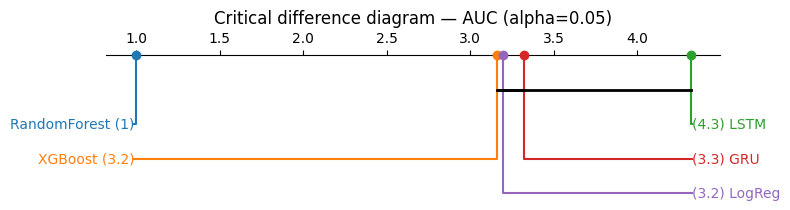

[Recall@top-25%] Friedman chi2 = 66.53, p = 1.22e-13
Mean ranks (lower = better):
model
RandomForest    1.64
GRU             2.10
LSTM            2.64
XGBoost         3.86
LogReg          4.76

Nemenyi p-values (pairs with p >= 0.05 are NOT separable):


model,GRU,LSTM,LogReg,RandomForest,XGBoost
model,,,,,
GRU,1.000,0.747,0.00,0.842,0.001
LSTM,0.747,1.000,0.00,0.166,0.050
LogReg,0.000,0.000,1.00,0.000,0.260
RandomForest,0.842,0.166,0.00,1.000,0.000
XGBoost,0.001,0.050,0.26,0.000,1.000


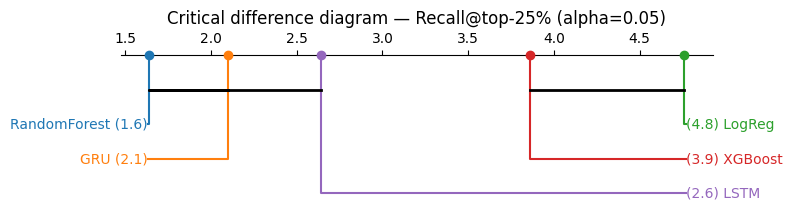

In [ ]:
def friedman_nemenyi(metric, title):
    piv = res.pivot_table(index=["week", "seed"], columns="model", values=metric)
    stat, p = stats.friedmanchisquare(*[piv[c] for c in piv.columns])
    print(f"[{title}] Friedman chi2 = {stat:.2f}, p = {p:.2e}")

    avg_rank = piv.rank(axis=1, ascending=False).mean().sort_values()
    print("Mean ranks (lower = better):")
    print(avg_rank.round(2).to_string())

    nemenyi = sp.posthoc_nemenyi_friedman(piv.values)
    nemenyi.index = nemenyi.columns = piv.columns
    print("\nNemenyi p-values (pairs with p >= 0.05 are NOT separable):")
    display(nemenyi.round(3))

    plt.figure(figsize=(8, 2.2))
    sp.critical_difference_diagram(avg_rank, nemenyi)
    plt.title(f"Critical difference diagram — {title} (alpha=0.05)")
    plt.tight_layout()
    plt.savefig(f"cd_diagram_{metric}.png", dpi=200, bbox_inches="tight")
    plt.show()
    return nemenyi

nem_auc = friedman_nemenyi("auc", "AUC")
nem_r25 = friedman_nemenyi("recall_top25", f"Recall@top-{int(ALERT_RATE*100)}%")

## 5. Final money figure: means with ±1 std bands

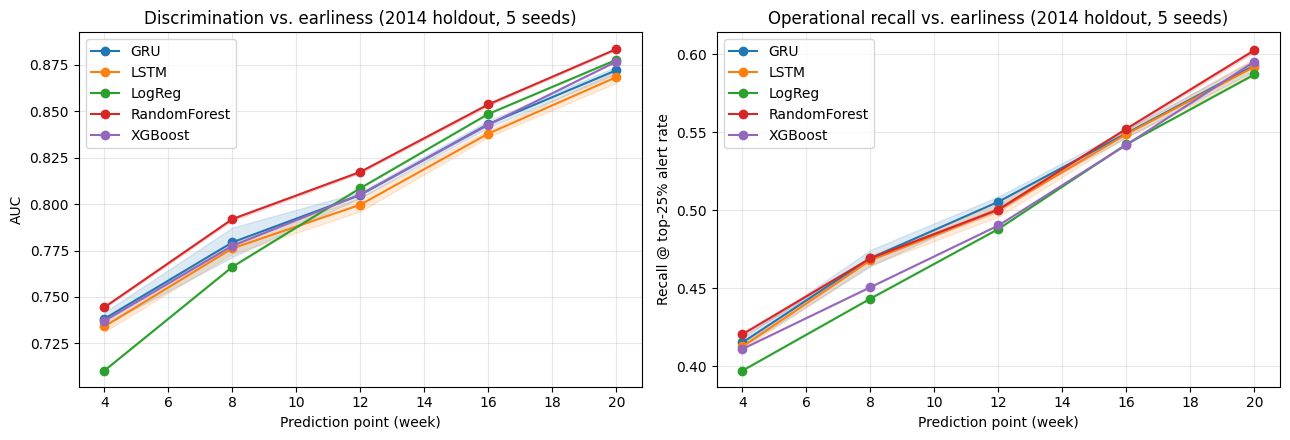

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for m, g in res.groupby("model"):
    for ax, metric in zip(axes, ["auc", "recall_top25"]):
        gm = g.groupby("week")[metric].agg(["mean", "std"]).reset_index()
        line, = ax.plot(gm.week, gm["mean"], marker="o", label=m)
        ax.fill_between(gm.week, gm["mean"] - gm["std"], gm["mean"] + gm["std"],
                        alpha=0.15, color=line.get_color())
axes[0].set(xlabel="Prediction point (week)", ylabel="AUC",
            title="Discrimination vs. earliness (2014 holdout, 5 seeds)")
axes[1].set(xlabel="Prediction point (week)",
            ylabel=f"Recall @ top-{int(ALERT_RATE*100)}% alert rate",
            title="Operational recall vs. earliness (2014 holdout, 5 seeds)")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig("money_figure_final.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. SHAP on the holdout protocol (consistency fix)

Same interpretability plot as before, but trained on the **2013 training
cohort** and explained on 2014 test students — so every figure in the paper
comes from one protocol.


/tmp/ipykernel_3699/95048124.py:17: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, sample, max_display=15, show=False)


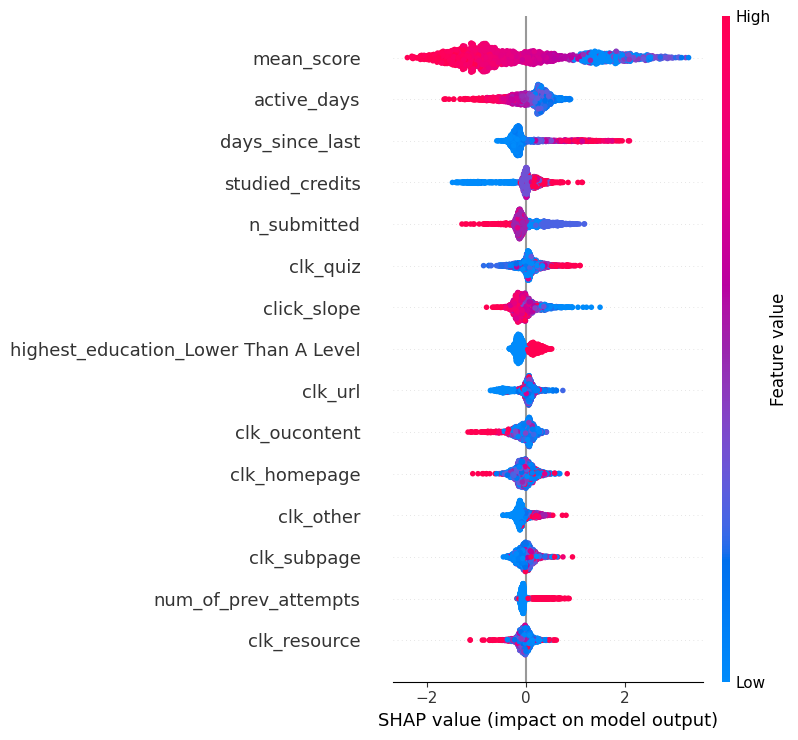

In [ ]:
import shap

H = 8
cohort = df[df.date_unregistration.isna() | (df.date_unregistration >= H * 7)]
cohort = cohort.reset_index(drop=True)
tr = np.where(cohort.code_presentation.isin(TRAIN_PRES))[0]
te = np.where(cohort.code_presentation.isin(TEST_PRES))[0]

Xtab, y = build_tabular(H, cohort)
Xtab.columns = [re.sub(r"\[|\]|<", "_", str(c)) for c in Xtab.columns]

model = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                          tree_method="hist", random_state=0)
model.fit(Xtab.iloc[tr], y[tr])
sample = Xtab.iloc[te].sample(2000, random_state=0)
sv = shap.TreeExplainer(model).shap_values(sample)
shap.summary_plot(sv, sample, max_display=15, show=False)
plt.savefig("shap_week8_holdout.png", dpi=300, bbox_inches="tight")
plt.show()

## Reading the outputs -> writing the Results section

* **RQ1 (ML vs DL at parity):** the AUC CD diagram is the answer. If a bar
  joins the best classical and best deep model, your sentence is
  "statistically indistinguishable on discrimination (Nemenyi, p = X)".
* **RQ2 (earliness):** the money figure. Describe how the gap (or tie)
  evolves from week 4 to 20, with the std bands as your uncertainty language.
* **RQ3 (cost/interpretability):** `secs_mean` column + the SHAP figure, plus
  the recall CD diagram if the deep models separate there.
* Download `results_multiseed.csv` and commit it to the repo — every number
  in the manuscript regenerates from this file.
